# Multilingual Text & Image Preprocessing

> **Cross-Lingual Intelligent Document Processing System**
>
> Technical demonstration · Arabic / English / German · Text & image preparation

<div dir="rtl" lang="ar" style="font-family: system-ui, 'Segoe UI', Tahoma, Arial, sans-serif; line-height: 1.8;">
<p>عرض تقني لمرحلة <b>Preprocessing</b> باستخدام أمثلة محلية قابلة لإعادة التشغيل، دون بيانات خاصة. يوضّح الدفتر تنظيف النص متعدد اللغات، وتقسيمه إلى مقاطع، وتهيئة صور المستندات.</p>
</div>

This notebook documents the preprocessing stage of the wider project. It does not implement a complete document-understanding or OCR system.

| Stage | Purpose | Demonstration |
| :--- | :--- | :--- |
| **01 · Text normalization** | Preserve meaningful multilingual content | Arabic, English, German; punctuation and currency |
| **02 · Word-based chunking** | Create overlapping segments | Chunk sizes, overlap, and input validation |
| **03 · Image preparation** | Prepare grayscale document images | Deterministic synthetic image; saved Before / After comparison |
| **04 · Validation & scope** | Document checks and boundaries | Executed assertions, test command, and limitations |

---

## 00 · Environment & reproducibility

| Item | Configuration |
| :--- | :--- |
| Python | **3.12.10** from the project `.venv` |
| Data | Local examples and a synthetic document; no private data |
| Image reproducibility | NumPy random seed **42** |
| Network | No dataset or OCR model downloads during execution |

<div dir="rtl" lang="ar" style="font-family: system-ui, 'Segoe UI', Tahoma, Arial, sans-serif; line-height: 1.8;">
<p>نفّذ الأوامر التالية من جذر المشروع. ثبّت المتطلبات عند إعداد البيئة، ثم اختر مفسّر <code dir="ltr">.venv</code> في VS Code واستخدم <b>Run All</b>، أو نفّذ الدفتر بالأداة المرفقة. تعرض الخلية التالية الإصدار الفعلي ومسار المفسّر والحزم المستخدمة.</p>
</div>

**Initial environment setup**

```powershell
.\.venv\Scripts\python.exe -m pip install -r requirements-preprocessing.txt
```

**Execute and save all notebook outputs**

```powershell
.\.venv\Scripts\python.exe notebooks/execute_notebook.py
```

The output immediately below records the environment used for the saved execution.

In [1]:
import sys
from pathlib import Path
from importlib.metadata import version

root = Path.cwd().resolve()
if not (root / 'idp_core').is_dir():
    root = root.parent
assert (root / 'idp_core').is_dir(), 'Run from the project or notebooks directory'
sys.path.insert(0, str(root))
assert sys.version_info[:3] == (3, 12, 10), sys.version
from idp_core.text_preprocessing import clean_text, chunk_text
from idp_core.ocr_preprocessing import preprocess_ocr_image
import numpy as np
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, Markdown
print('Python:', sys.version)
print('Executable:', sys.executable)
for package in ('numpy', 'opencv-python', 'Pillow', 'nbformat', 'nbclient', 'ipykernel'):
    print(package, version(package))

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Executable: C:\AI-Projects\NLP_MultiLang\.venv\Scripts\python.exe
numpy 2.5.4
opencv-python 5.0.0.93
Pillow 13.0.0
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0


## 01 · Multilingual text normalization

**Function:** `clean_text(text)` · **Output:** normalized `str`

<div dir="rtl" lang="ar" style="font-family: system-ui, 'Segoe UI', Tahoma, Arial, sans-serif; line-height: 1.8;">
<p>توحّد الدالة التمثيلات المتكافئة باستخدام <span dir="ltr">Unicode NFC</span>، وتستبدل <span dir="ltr">control characters</span> بمسافات، ثم تدمج المسافات المتتابعة. تحافظ على التشكيل وأسماء الأعلام وعلامات الترقيم والرموز المهمة، بدل حذفها بقائمة سماح محدودة.</p>
<p><b>حدّ مهم:</b> تُدمج فواصل الأسطر أيضًا؛ لذلك يُحتفظ بالنص الأصلي منفصلًا عند الحاجة إلى تخطيط الفقرات أو الجداول.</p>
</div>

| Example | Content retained | Check illustrated |
| :--- | :--- | :--- |
| Arabic · العربية | Diacritics, Arabic digits, `%`, `-`, currency | Meaningful symbols survive cleaning |
| English | Apostrophes, hyphens, `$`, `£` | Contractions and financial values remain intact |
| German · Deutsch | Umlauts, `ß`, `€` | Decomposed characters are normalized to NFC |

### Before / After · Reading the saved results

- **Before** shows `repr(original)`, making line breaks and surrounding spaces inspectable.
- **After** shows the normalized text. Each example checks **idempotence**: cleaning an already cleaned value leaves it unchanged.

<div dir="rtl" lang="ar"><p>تظهر الأمثلة أدناه بحسب اللغة، مع إبقاء نتائج التنفيذ الأصلية كاملة للمقارنة.</p></div>

In [2]:
samples = {
    'العربية': '  عَقْدٌ تجاريّ:   خصم -10%، السعر ٥٠ ر.س.\nالتسليم غدًا.  ',
    'English': "  Don't remove -10% or $25.50!\nKeep E-Mail and £5.  ",
    'Deutsch': '  Fu\u0308r die Straße:   25€ — E-Mail bleibt erhalten.  ',
}
for language, original in samples.items():
    cleaned = clean_text(original)
    display(Markdown(f'### {language}'))
    print('Before:', repr(original))
    print('After: ', cleaned)
    assert clean_text(cleaned) == cleaned
assert '-10%' in clean_text(samples['العربية'])
assert "Don't" in clean_text(samples['English'])
assert 'Für' in clean_text(samples['Deutsch'])

### العربية

Before: '  عَقْدٌ تجاريّ:   خصم -10%، السعر ٥٠ ر.س.\nالتسليم غدًا.  '
After:  عَقْدٌ تجاريّ: خصم -10%، السعر ٥٠ ر.س. التسليم غدًا.


### English

Before: "  Don't remove -10% or $25.50!\nKeep E-Mail and £5.  "
After:  Don't remove -10% or $25.50! Keep E-Mail and £5.


### Deutsch

Before: '  Für die Straße:   25€ — E-Mail bleibt erhalten.  '
After:  Für die Straße: 25€ — E-Mail bleibt erhalten.


## 02 · Word-based chunking

**Function:** `chunk_text(text, chunk_size=300, overlap=50)` · **Output:** `list[str]`

<div dir="rtl" lang="ar" style="font-family: system-ui, 'Segoe UI', Tahoma, Arial, sans-serif; line-height: 1.8;">
<p>يقسّم النص إلى مقاطع وفق الكلمات المفصولة بـ <span dir="ltr">whitespace</span>، مع تداخل يحافظ على جزء من السياق. تتوقف الدالة عند تغطية نهاية النص لتجنّب مقطع أخير مكرر بالكامل.</p>
</div>

| Parameter | Default | Demonstration | Constraint |
| :--- | ---: | ---: | :--- |
| `chunk_size` | 300 words | 12 words | Integer greater than zero |
| `overlap` | 50 words | 3 words | Integer; `0 <= overlap < chunk_size` |

**Interpretation:** the sizes count words, not model tokens. Sentence boundaries are not detected.

### Saved execution

The following cell displays the multilingual chunks and exercises exact-length input, empty input, and invalid parameters. The validation messages are **expected exceptions handled by the demonstration**, not failed notebook cells.

In [3]:
combined = clean_text(' '.join(samples.values()))
chunks = chunk_text(combined, chunk_size=12, overlap=3)
for index, chunk in enumerate(chunks, 1):
    print(f'Chunk {index} ({len(chunk.split())} words): {chunk}')
assert chunk_text('A B C D', 4, 1) == ['A B C D']
assert chunk_text('') == []
for operation in (lambda: chunk_text('a b', 2, 2), lambda: clean_text(None)):
    try:
        operation()
    except (ValueError, TypeError) as error:
        print(type(error).__name__ + ':', error)
    else:
        raise AssertionError('Expected input validation error')

Chunk 1 (12 words): عَقْدٌ تجاريّ: خصم -10%، السعر ٥٠ ر.س. التسليم غدًا. Don't remove -10%
Chunk 2 (12 words): Don't remove -10% or $25.50! Keep E-Mail and £5. Für die Straße:
Chunk 3 (8 words): Für die Straße: 25€ — E-Mail bleibt erhalten.
ValueError: overlap must satisfy 0 <= overlap < chunk_size
TypeError: text must be a string


## 03 · Image preprocessing

**Function:** `preprocess_ocr_image(image_path_or_obj)` · **Output:** grayscale `uint8` array

<div dir="rtl" lang="ar" style="font-family: system-ui, 'Segoe UI', Tahoma, Arial, sans-serif; line-height: 1.8;">
<p>تُولَّد صورة مستند محلية بإضاءة غير متجانسة وضوضاء قابلة لإعادة الإنتاج باستخدام <span dir="ltr">seed=42</span>. تُهيَّأ الصورة دون تعديل المدخل الأصلي، وتُعرض النسختان قبل المعالجة وبعدها.</p>
</div>

### Processing sequence

| Step | Operation | Setting / contract |
| :--- | :--- | :--- |
| **1** | Convert to grayscale | Correct RGB / BGR interpretation |
| **2** | Mild denoising | `h=10` |
| **3** | Local contrast enhancement | CLAHE |

| Input | Color convention | Handling |
| :--- | :--- | :--- |
| File path | Loaded through PIL | String or `PathLike` |
| PIL image | RGB / RGBA conversion | Alpha composited on white |
| NumPy array | Grayscale, BGR, or BGRA | `uint8`; alpha composited on white |

> **Evaluation boundary:** a visible change is not evidence of improved OCR accuracy. No CER/WER claim is made.

### Original experiment & saved outputs

The code and its original Before / After outputs remain below. A compact side-by-side view of the **same saved PNG images** follows the experiment.

### Before — الصورة الأصلية التجريبية

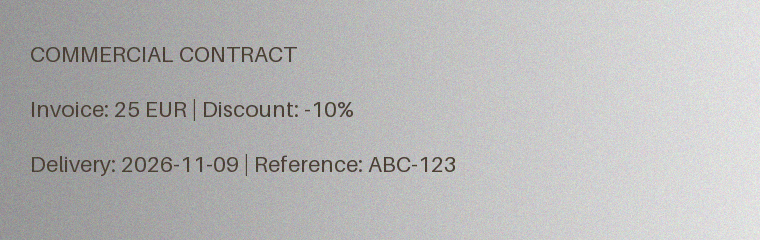

### After — بعد المعالجة

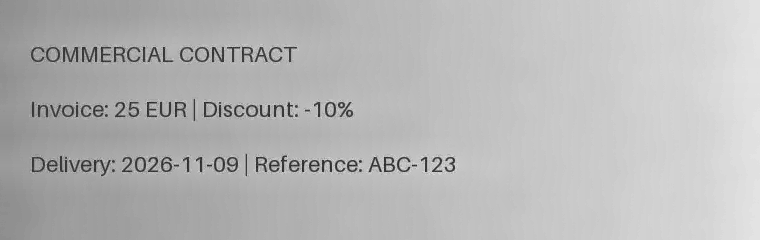

Verified: PIL RGB and NumPy BGR give identical results.


In [4]:
width, height = 760, 240
background = np.tile(np.linspace(150, 225, width), (height, 1))
document = Image.fromarray(background.astype(np.uint8)).convert('RGB')
draw = ImageDraw.Draw(document)
font = ImageFont.load_default(size=22)
for y, line in enumerate(('COMMERCIAL CONTRACT', 'Invoice: 25 EUR | Discount: -10%', 'Delivery: 2026-11-09 | Reference: ABC-123')):
    draw.text((30, 40 + y * 55), line, fill=(75, 65, 55), font=font)
rng = np.random.default_rng(42)
noisy = np.clip(np.array(document).astype(float) + rng.normal(0, 7, (height, width, 3)), 0, 255).astype(np.uint8)
before = Image.fromarray(noisy)
after_array = preprocess_ocr_image(before)
after = Image.fromarray(after_array)
assert after_array.shape == (height, width)
assert after_array.dtype == np.uint8
display(Markdown('### Before — الصورة الأصلية التجريبية'))
display(before)
display(Markdown('### After — بعد المعالجة'))
display(after)
bgr = noisy[:, :, ::-1].copy()
np.testing.assert_array_equal(preprocess_ocr_image(bgr), after_array)
print('Verified: PIL RGB and NumPy BGR give identical results.')

### Before / After · Side-by-side comparison

| **Before · Synthetic input** | **After · Preprocessed output** |
| :---: | :---: |
| 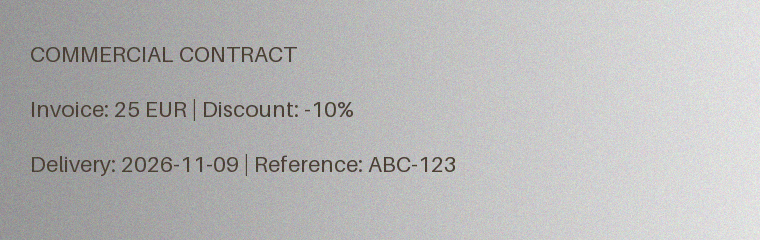 | 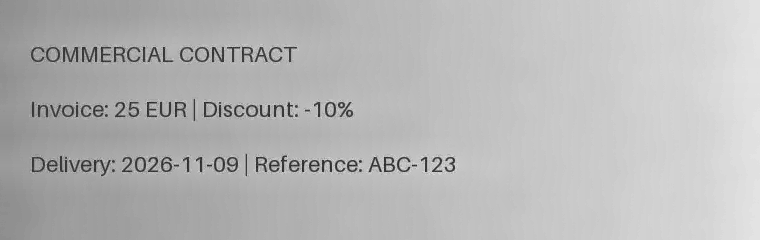 |
| Local RGB image with deterministic noise | Grayscale → denoising → CLAHE |

<div dir="rtl" lang="ar" style="font-family: system-ui, 'Segoe UI', Tahoma, Arial, sans-serif; line-height: 1.8;">
<p>الصورتان أعلاه نسختان مطابقتان للصور المحفوظة في مخرجات التجربة، وبالأبعاد نفسها لتسهيل المقارنة. تبقى المخرجات الأصلية محفوظة دون تغيير. المقارنة بصرية فقط ولا تثبت زيادة دقة <span dir="ltr">OCR</span>.</p>
</div>

## 04 · Validation, scope & limitations

### Verification recorded in the notebook

| Area | Executed checks |
| :--- | :--- |
| Environment | Python 3.12.10; interpreter path and package versions printed |
| Text | Idempotence; Arabic financial symbols; English apostrophe; German NFC example |
| Chunking | Exact-length input; empty input; handled invalid-parameter cases |
| Images | Output dimensions and dtype; identical PIL RGB / NumPy BGR results |

These are the existing demonstration checks, not additional performance measurements. Detailed unit-test results remain in [TEST_REPORT.md](../tests/TEST_REPORT.md).

### Run the unit tests

```powershell
.\.venv\Scripts\python.exe -m unittest discover -s tests -v
```

### Scientific boundaries

<div dir="rtl" lang="ar" style="font-family: system-ui, 'Segoe UI', Tahoma, Arial, sans-serif; line-height: 1.8;">
<p>هذا الدفتر يوثّق مرحلة <b>Preprocessing</b> فقط. لا يتضمن استخراج النص بمحرك <span dir="ltr">OCR</span>، أو إدخال <span dir="ltr">PDF</span>، أو <span dir="ltr">embeddings</span>، أو نظام <span dir="ltr">RAG</span> متكاملًا.</p>
</div>

| Boundary | Practical implication |
| :--- | :--- |
| No measured OCR accuracy | Evaluation requires reference documents and CER/WER |
| No automatic spelling or diacritic removal | Names and original meaning are preserved |
| Flattened text whitespace | Keep original text for paragraph and table layout |
| Word-based chunks | No sentence segmentation or model-token budget guarantee |
| NumPy image contract | `uint8` grayscale / BGR / BGRA only; invalid inputs are rejected |
| Image scope | No deskew or multipage PDF processing |

---

*All examples are local. No external fonts, images, or remote assets are required.*